# TP1 : Prétraitement d'un dataset

**Matériel** **requis**

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

**Partie 1 : Introduction au dataset**

In [47]:
df = pd.read_csv("Titanic-Dataset.csv")
print(df.shape)

(891, 12)


In [48]:
#Types de données
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [49]:
#Les premiers lignes
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [50]:
#Les valeurs manquantes
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


#Partie 2 : Nettoyage des Données

**1. Gestion des valeurs manquantes :**

In [51]:
#séparer train et test
from sklearn.model_selection import train_test_split

X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

X_train = X_train.copy()
X_test = X_test.copy()
print(X_train.shape, X_test.shape)

(712, 11) (179, 11)


In [52]:
#Afficher le pourcentage de cases vides pour chaque colonne
print((X_train.isna().mean() * 100).round(1))

PassengerId     0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.2
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.5
Embarked        0.3
dtype: float64


In [53]:
#supprimer les colonnes à plus de 40 % valeurs manquantes
taux = X_train.isna().mean() * 100
cols_to_drop = taux[taux > 40].index
print("Colonnes à supprimer :", list(cols_to_drop))

X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

Colonnes à supprimer : ['Cabin']


In [54]:
from sklearn.impute import SimpleImputer

# Sélectionner les colonnes numériques
numeric_cols = X_train.select_dtypes(include="number").columns

# Remplacer les valeurs manquantes par la médiane
imputer_num = SimpleImputer(strategy="median")

X_train[numeric_cols] = imputer_num.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = imputer_num.transform(X_test[numeric_cols])

In [55]:
# Sélectionner les colonnes catégorielles
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns

# Remplacer les valeurs manquantes par le mode
imputer_cat = SimpleImputer(strategy="most_frequent")

X_train[categorical_cols] = imputer_cat.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = imputer_cat.transform(X_test[categorical_cols])

**2. Gestion des valeurs aberrantes :**

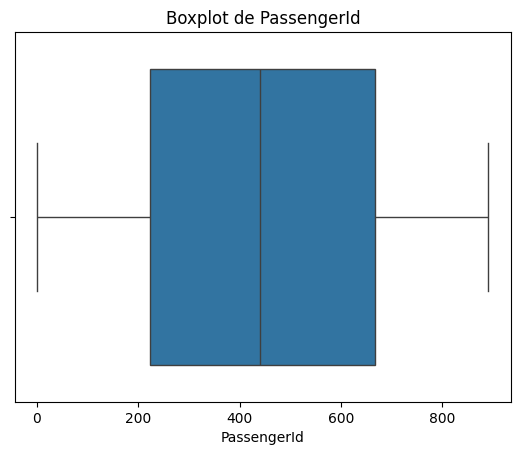

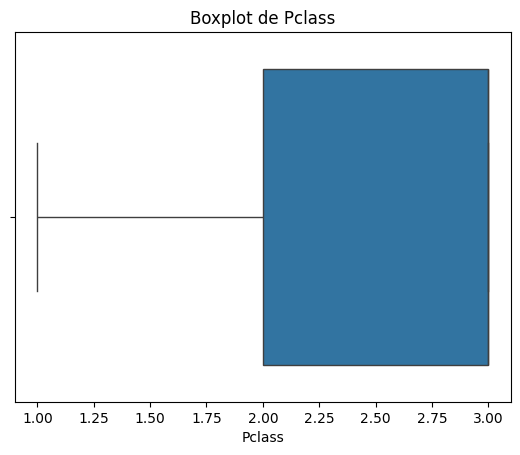

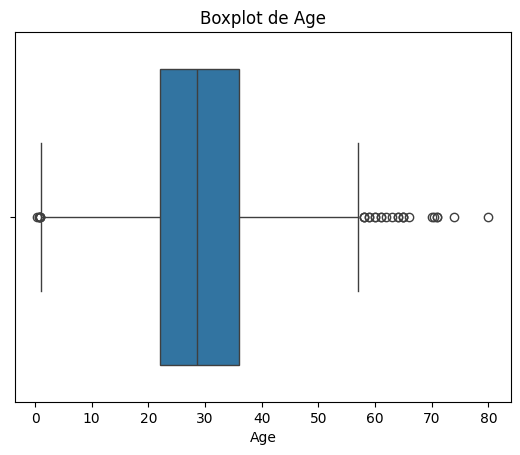

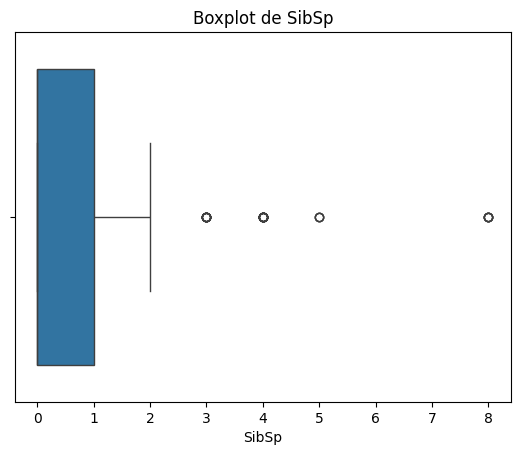

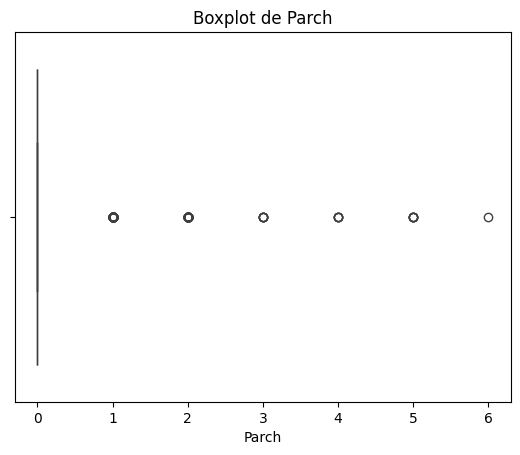

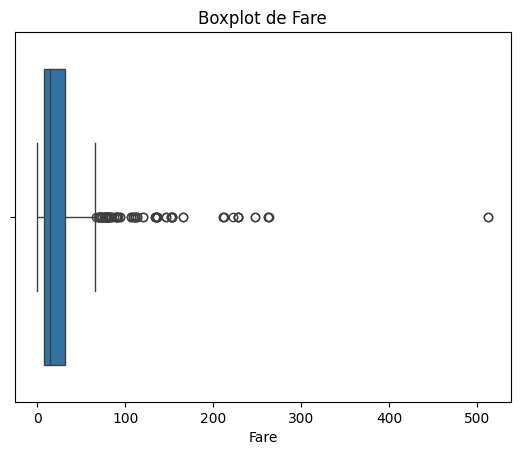

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher les boxplots des variables numériques
for col in numeric_cols:
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

In [57]:
import numpy as np

cols_outliers = ["Age", "Fare"]

for col in cols_outliers:
    # Calculer Q1 et Q3 UNIQUEMENT sur le train
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    median = X_train[col].median()

    print(f"{col} → bornes [{lower_bound:.1f}, {upper_bound:.1f}], médiane = {median:.1f}")

    # Remplacer les outliers par la médiane (sur train ET test)
    X_train[col] = np.where(
        (X_train[col] < lower_bound) | (X_train[col] > upper_bound),
        median,
        X_train[col]
    )
    X_test[col] = np.where(
        (X_test[col] < lower_bound) | (X_test[col] > upper_bound),
        median,
        X_test[col]
    )

Age → bornes [1.0, 57.0], médiane = 28.5
Fare → bornes [-26.8, 65.7], médiane = 14.5


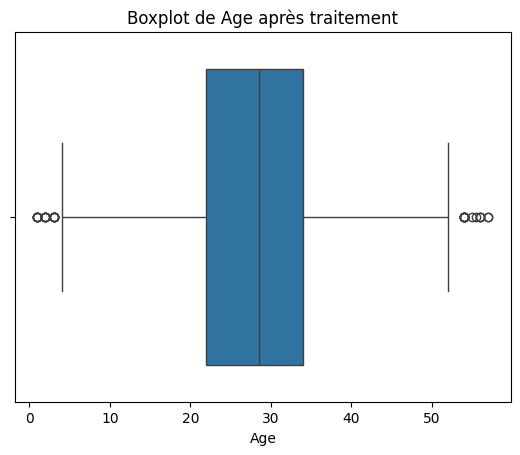

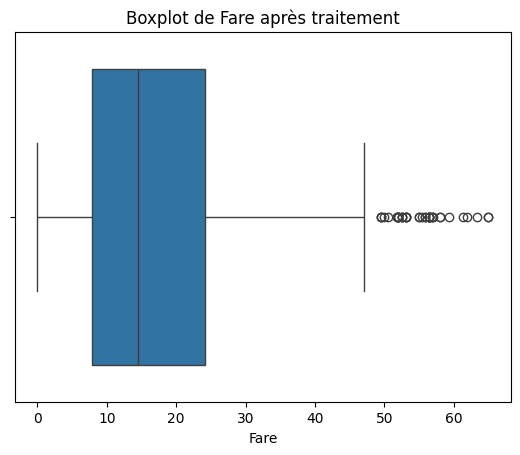

In [58]:
for col in ["Age", "Fare"]:
    sns.boxplot(x=X_train[col])
    plt.title(f"Boxplot de {col} après traitement")
    plt.show()

#Partie 3 : Transformation des données

**1. Encodage des variables catégorielles :**

In [59]:
# Identifier les variables catégorielles restantes
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables catégorielles :", categorical_cols)

Variables catégorielles : ['Name', 'Sex', 'Ticket', 'Embarked']


In [60]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Colonnes nominales (sans ordre)
nominal_cols = ["Sex", "Embarked"]

# Créer l'encodeur
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)

# Apprendre UNIQUEMENT sur le train
X_train_encoded = encoder.fit_transform(X_train[nominal_cols])
X_test_encoded  = encoder.transform(X_test[nominal_cols])

# Noms des nouvelles colonnes
encoded_cols = encoder.get_feature_names_out(nominal_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded, columns=encoded_cols, index=X_train.index
)
X_test_encoded = pd.DataFrame(
    X_test_encoded, columns=encoded_cols, index=X_test.index
)

# Remplacer les colonnes originales par les colonnes one-hot
X_train = pd.concat([X_train.drop(columns=nominal_cols), X_train_encoded], axis=1)
X_test  = pd.concat([X_test.drop(columns=nominal_cols),  X_test_encoded],  axis=1)

print("Colonnes après encodage :")
print(list(X_train.columns))

Colonnes après encodage :
['PassengerId', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


**2. Normalisation et Standardisation des données :**

In [61]:
# Identifier les variables numériques (après encodage)
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
print("Colonnes numériques à scaler :", numeric_cols)

Colonnes numériques à scaler : ['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


In [62]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()

X_train_minmax = X_train.copy()
X_test_minmax  = X_test.copy()

# fit uniquement sur le train
X_train_minmax[numeric_cols] = minmax.fit_transform(X_train[numeric_cols])
X_test_minmax[numeric_cols]  = minmax.transform(X_test[numeric_cols])

In [63]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard  = X_test.copy()

# fit uniquement sur le train
X_train_standard[numeric_cols] = standard.fit_transform(X_train[numeric_cols])
X_test_standard[numeric_cols]  = standard.transform(X_test[numeric_cols])

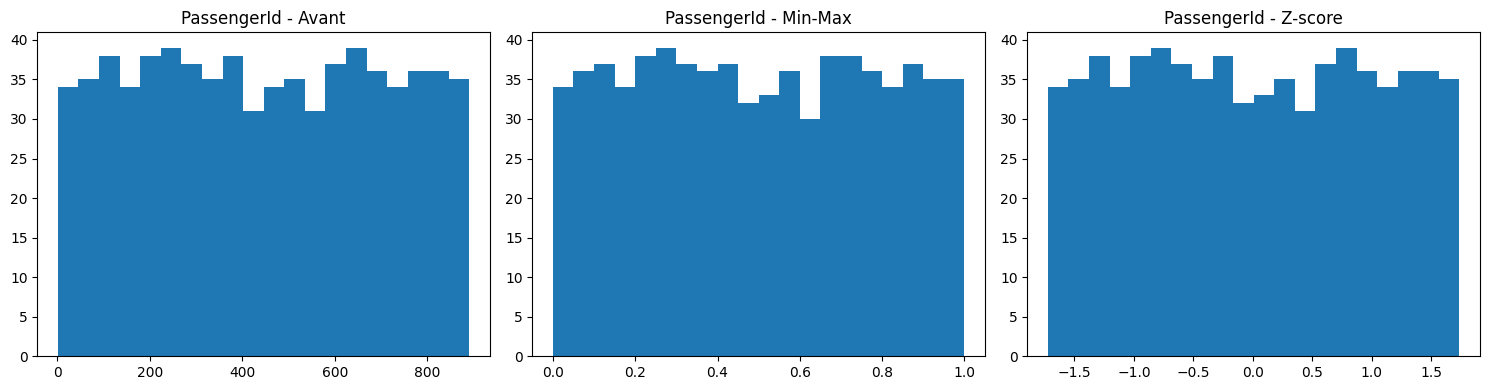

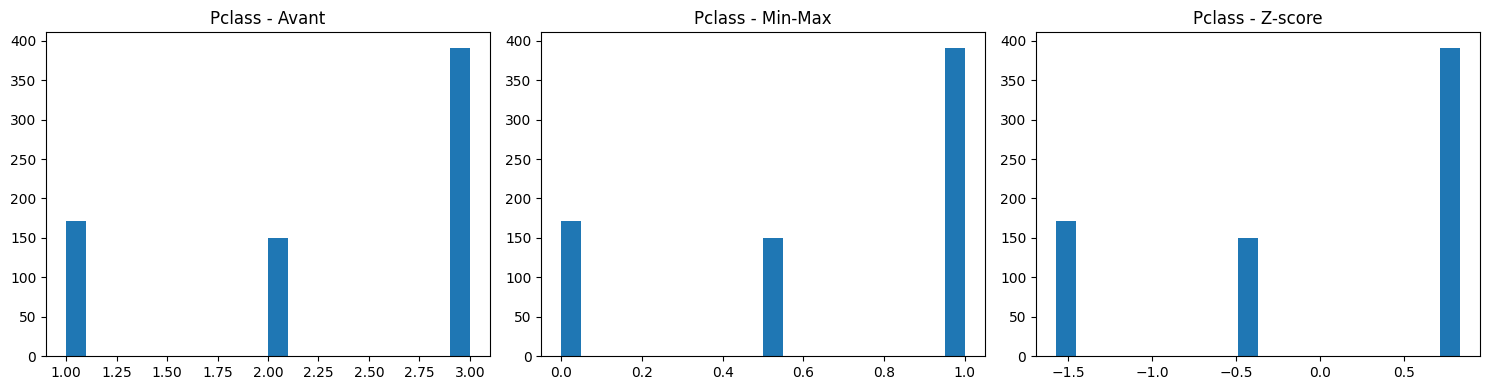

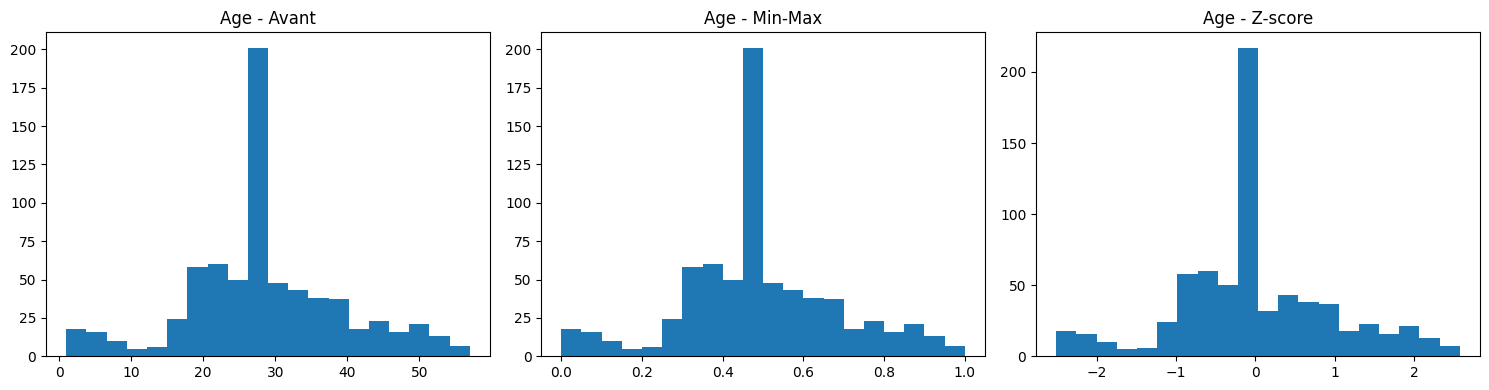

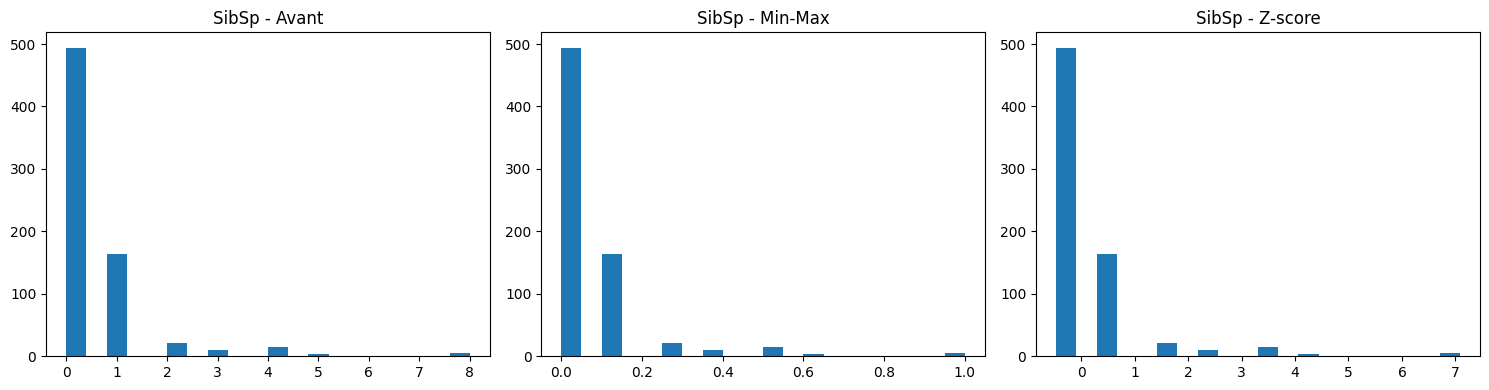

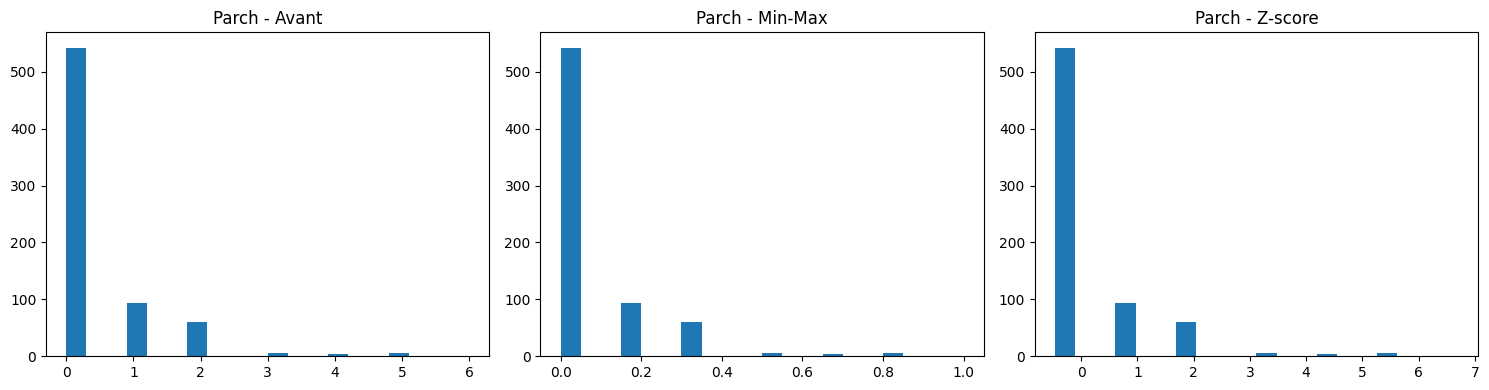

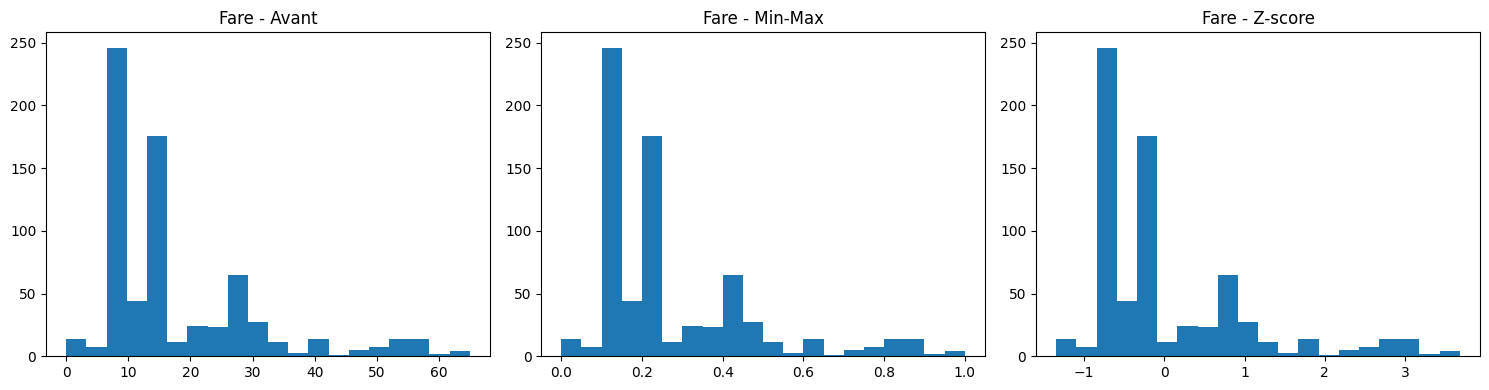

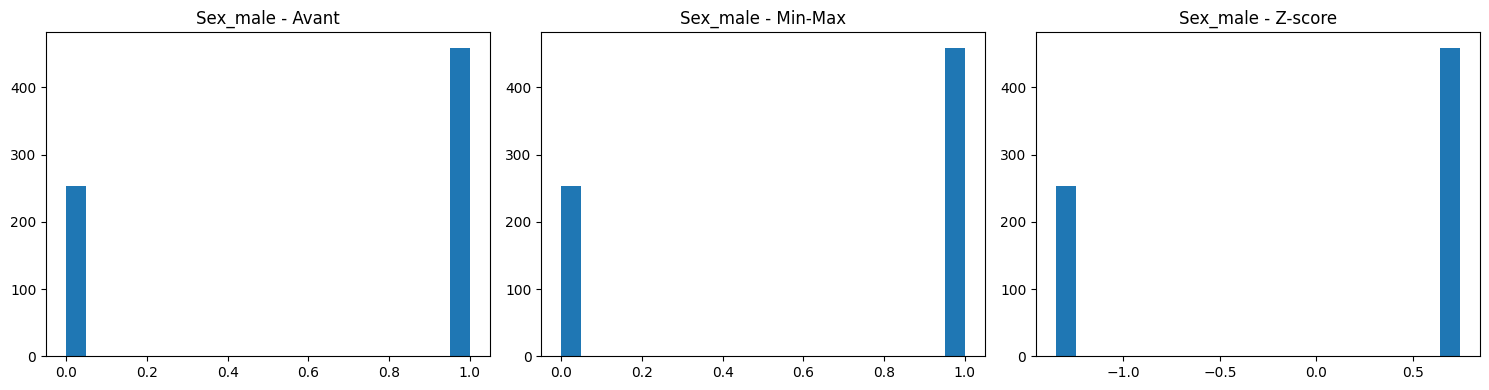

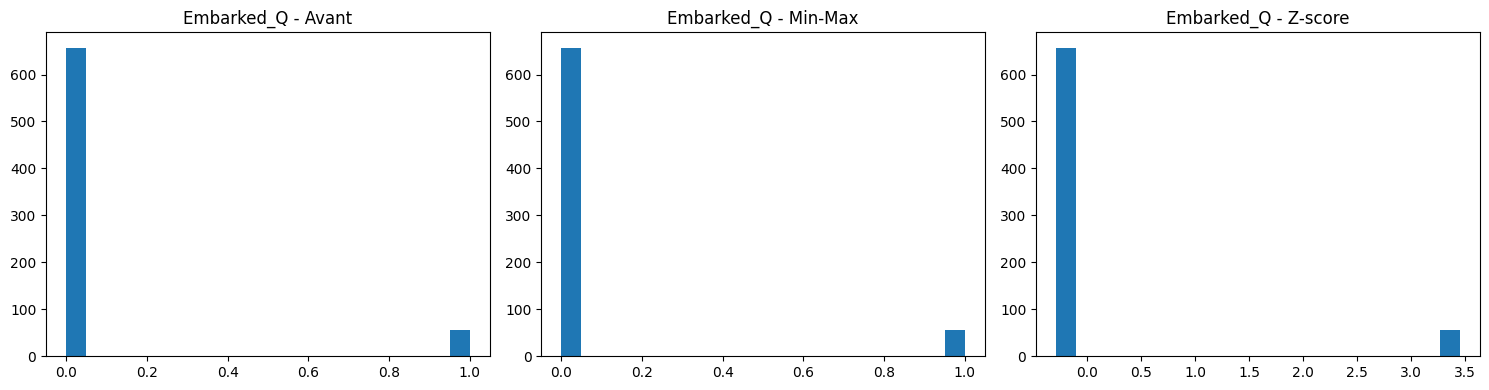

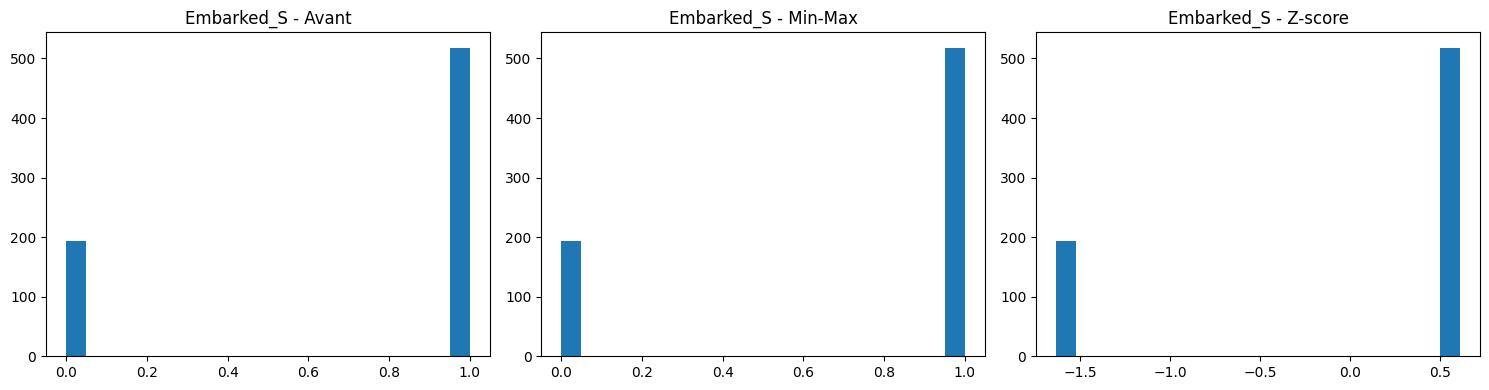

In [64]:
import matplotlib.pyplot as plt

for col in numeric_cols:

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist(X_train[col], bins=20)
    axes[0].set_title(f"{col} - Avant")

    axes[1].hist(X_train_minmax[col], bins=20)
    axes[1].set_title(f"{col} - Min-Max")

    axes[2].hist(X_train_standard[col], bins=20)
    axes[2].set_title(f"{col} - Z-score")

    plt.tight_layout()
    plt.show()

#Partie 4 : Gestion des Données Déséquilibrées

**1. Identification du déséquilibre des classes :**

In [65]:
# Afficher le nombre d'exemples de chaque classe
print(y_train.value_counts())

Survived
0    439
1    273
Name: count, dtype: int64


In [66]:
print(y_train.value_counts(normalize=True) * 100)

Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


**2. Gestion du déséquilibre:**

In [67]:
from imblearn.under_sampling import RandomUnderSampler

under = RandomUnderSampler(random_state=42)

# Appliquer uniquement sur le train
X_train_under, y_train_under = under.fit_resample(X_train_minmax, y_train)

print("Avant undersampling :")
print(y_train.value_counts())
print("\nAprès Undersampling :")
print(y_train_under.value_counts())

Avant undersampling :
Survived
0    439
1    273
Name: count, dtype: int64

Après Undersampling :
Survived
0    273
1    273
Name: count, dtype: int64


In [68]:
from imblearn.over_sampling import SMOTE

# Créer la méthode
smote = SMOTE(random_state=42)

# Appliquer uniquement sur le train
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_minmax.select_dtypes(include="number").drop(
        columns=["PassengerId"], errors="ignore"
    ),
    y_train
)

# Vérifier le résultat
print("Avant SMOTE :")
print(y_train.value_counts())

print("Après SMOTE :")
print(y_train_smote.value_counts())

Avant SMOTE :
Survived
0    439
1    273
Name: count, dtype: int64
Après SMOTE :
Survived
1    439
0    439
Name: count, dtype: int64
